## calculate the distance between two hands (USING MEDIAPIPE)

In [38]:
import cv2
import math
import urllib.request
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

In [39]:
url = ("https://storage.googleapis.com/mediapipe-models/"
       "hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task")
urllib.request.urlretrieve(url, "hand_landmarker.task")
print("Model downloaded")

Model downloaded


In [40]:
options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="hand_landmarker.task"),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.7,
    min_tracking_confidence=0.5,
)
detector = vision.HandLandmarker.create_from_options(options)

In [41]:
def get_hand_centers(frame):
    """Detects hands, draws their landmarks, returns one (x, y) pixel point per hand."""
    h, w, _ = frame.shape
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = detector.detect(mp_image)

    centers = []
    for hand in result.hand_landmarks:       # one list of 21 landmarks per hand
        # draw all 21 points (the old drawing helper no longer exists)
        for lm in hand:
            cv2.circle(frame, (int(lm.x * w), int(lm.y * h)), 3, (0, 255, 255), -1)

        # Landmark 9 = base of the middle finger, roughly the palm center
        point = hand[9]
        centers.append((int(point.x * w), int(point.y * h)))
    return centers

In [42]:
def draw_distance(frame, centers):
    if len(centers) == 2:
        p1, p2 = sorted(centers)   # sorted by x: left hand, right hand on screen

        distance = math.hypot(p2[0] - p1[0], p2[1] - p1[1])

        cv2.circle(frame, p1, 8, (0, 255, 0), -1)
        cv2.circle(frame, p2, 8, (0, 255, 0), -1)
        cv2.line(frame, p1, p2, (255, 0, 0), 3)

        middle = ((p1[0] + p2[0]) // 2, (p1[1] + p2[1]) // 2)
        cv2.putText(frame, f"{int(distance)} px", middle,
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    else:
        cv2.putText(frame, "Show both hands", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    return frame

In [43]:
cap = cv2.VideoCapture(0)

while True:
    ok, frame = cap.read()
    if not ok:
        break

    frame = cv2.flip(frame, 1)
    centers = get_hand_centers(frame)
    frame = draw_distance(frame, centers)

    cv2.imshow("Hand distance", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

### calculate distance between two hands

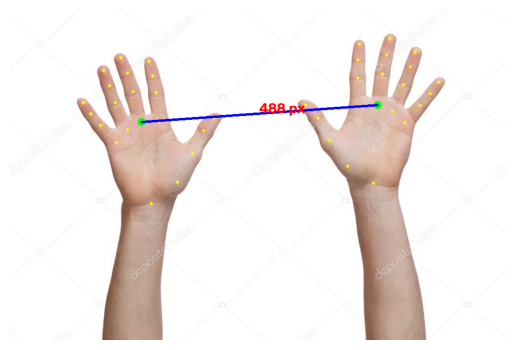

In [45]:
import matplotlib.pyplot as plt

frame = cv2.imread("hands.jpg") 
centers = get_hand_centers(frame)
frame = draw_distance(frame, centers)

plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()